In [7]:
from pathlib import Path
import polars as pl

carpeta = Path("/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/data/output")

archivos = [
    a for a in sorted(carpeta.glob("*_clone-pass.tsv"))
    if a.stem.split("_")[1] in ["A", "B", "C", "D", "E"]
]
print("Archivos encontrados:", len(archivos))
assert len(archivos) == 55

tablas = []

for archivo in archivos:
    partes = archivo.stem.split("_")
    escenario = partes[1]
    profundidad = int(partes[3])

    df = pl.read_csv(
        archivo,
        separator="\t",
        columns=["clone_id", "v_call", "j_call", "junction"],
        infer_schema_length=0,
        null_values=["NA"],
    )
    n_total = df.height

    top5 = (
        df.group_by("clone_id")
        .agg(
            pl.len().alias("n_secuencias"),
            pl.col("v_call").first(),
            pl.col("j_call").first(),
            pl.col("junction").first(),
        )
        .sort(["n_secuencias", "clone_id"], descending=[True, False])
        .head(5)
        .with_columns(
            escenario=pl.lit(escenario),
            profundidad=pl.lit(profundidad),
            ranking=pl.int_range(1, pl.len() + 1),
            porcentaje=(pl.col("n_secuencias") / n_total * 100).round(3),
        )
        .select(["escenario", "profundidad", "ranking", "clone_id",
                 "n_secuencias", "porcentaje", "v_call", "j_call", "junction"])
    )
    tablas.append(top5)

top5_todos = pl.concat(tablas).sort(["escenario", "profundidad", "ranking"])
print(top5_todos)

top5_todos.write_csv(
    "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/clonal_table/top5_clones.tsv",
    separator="\t",
    )
    

Archivos encontrados: 55
shape: (275, 9)
┌───────────┬────────────┬─────────┬──────────┬───┬────────────┬────────────┬──────────┬───────────┐
│ escenario ┆ profundida ┆ ranking ┆ clone_id ┆ … ┆ porcentaje ┆ v_call     ┆ j_call   ┆ junction  │
│ ---       ┆ d          ┆ ---     ┆ ---      ┆   ┆ ---        ┆ ---        ┆ ---      ┆ ---       │
│ str       ┆ ---        ┆ i64     ┆ str      ┆   ┆ f64        ┆ str        ┆ str      ┆ str       │
│           ┆ i32        ┆         ┆          ┆   ┆            ┆            ┆          ┆           │
╞═══════════╪════════════╪═════════╪══════════╪═══╪════════════╪════════════╪══════════╪═══════════╡
│ A         ┆ 100        ┆ 1       ┆ 1        ┆ … ┆ 1.0        ┆ IGHV4-34*0 ┆ IGHJ6*01 ┆ TGTGCGAGA │
│           ┆            ┆         ┆          ┆   ┆            ┆ 1          ┆          ┆ GGTACTAAC │
│           ┆            ┆         ┆          ┆   ┆            ┆            ┆          ┆ TACTACTAC │
│           ┆            ┆         ┆          ┆   

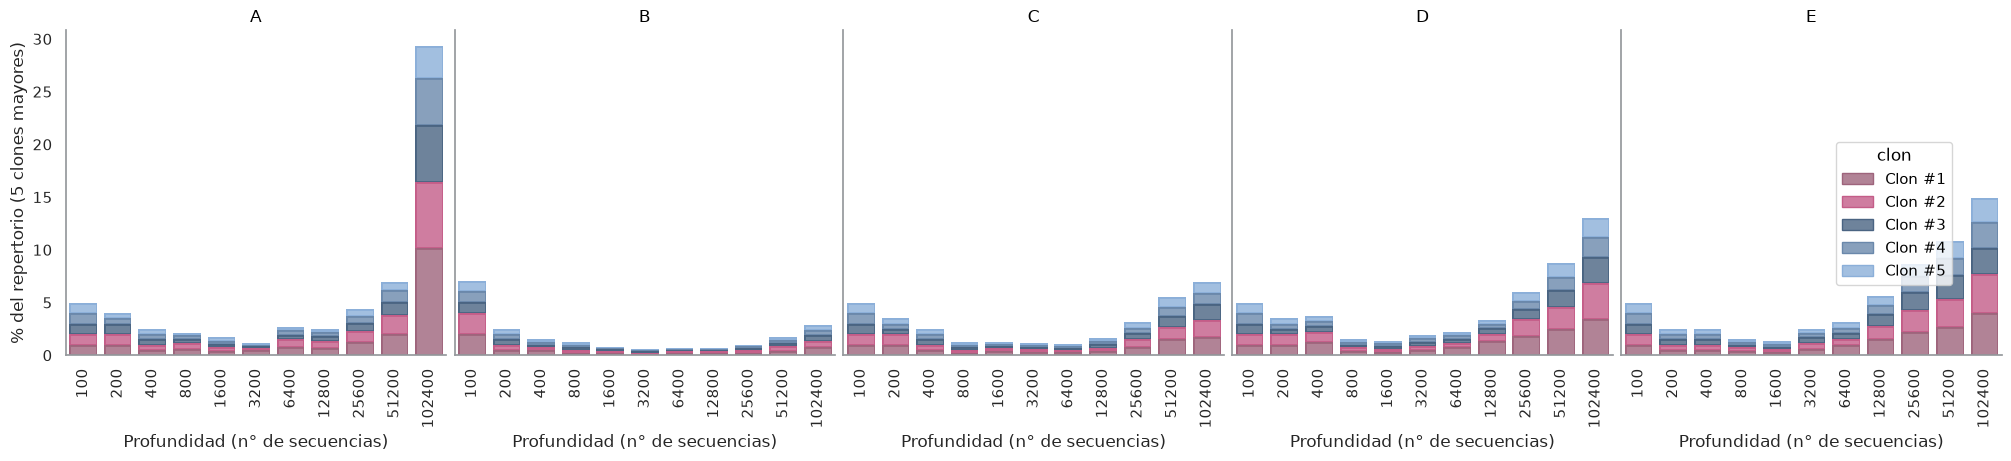

In [8]:
import polars as pl
import seaborn.objects as so
from seaborn import axes_style
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300

# Misma paleta del gráfico de espacio clonal:
# rosados para los clones más grandes, azules para los más pequeños
colormap_top5 = {
    "Clon #1": "#9e647c",
    "Clon #2": "#c45d88",
    "Clon #3": "#4a6482",
    "Clon #4": "#6a88ab",
    "Clon #5": "#8bafd9",
}

# Preparar los datos
df_plot = top5_todos.with_columns(
    profundidad_lbl=pl.col("profundidad").cast(pl.Utf8),
    clon=pl.concat_str(pl.lit("Clon #"), pl.col("ranking").cast(pl.Utf8)),
).sort(["escenario", "profundidad", "ranking"])

orden_prof = [str(p) for p in sorted(top5_todos["profundidad"].unique().to_list())]

plot = (
    so.Plot(
        df_plot,
        x="profundidad_lbl",
        y="porcentaje",
        color="clon",
    )
    .facet(col="escenario")
    .add(so.Bar(alpha=0.8, width=0.8), so.Stack(), legend=True)
    .scale(color=colormap_top5, x=so.Nominal(order=orden_prof))
    .label(x="Profundidad (n° de secuencias)",
           y="% del repertorio (5 clones mayores)")
    .layout(size=(20, 4.5), engine="constrained")
    .theme(
        {
            "axes.edgecolor": "#95999d",
            "axes.spines.right": False,
            "axes.spines.top": False,
        }
    )
)

plot.config.theme.update(axes_style("white"))

fig = plot.plot(pyplot=True)

# Girar las etiquetas del eje X para que no se superpongan
for ax in fig._figure.axes:
    ax.tick_params(axis="x", labelrotation=90)

ruta = "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/plots/top5_clones"
fig._figure.savefig(ruta + ".png", dpi=300, bbox_inches="tight", facecolor="white")
fig._figure.savefig(ruta + ".svg", format="svg", bbox_inches="tight")


In [9]:
import re
from pathlib import Path
import polars as pl

carpeta = Path("/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/data/shm_12_folicular")

archivos = sorted(carpeta.glob("repertorio_D_insilico_*_seqs_shm12_clone-pass.tsv"))  # glob no entra a subcarpetas
print("Archivos encontrados:", len(archivos))
assert len(archivos) == 11

tablas = []

for archivo in archivos:
    profundidad = int(re.search(r"_(\d+)_seqs", archivo.stem).group(1))

    df = pl.read_csv(
        archivo,
        separator="\t",
        columns=["clone_id", "v_call", "j_call", "junction"],
        infer_schema_length=0,
        null_values=["NA"],
    )
    n_total = df.height

    top5 = (
        df.group_by("clone_id")
        .agg(
            pl.len().alias("n_secuencias"),
            pl.col("v_call").first(),
            pl.col("j_call").first(),
            pl.col("junction").first(),
        )
        .sort(["n_secuencias", "clone_id"], descending=[True, False])
        .head(5)
        .with_columns(
            escenario=pl.lit("D_shm12"),
            profundidad=pl.lit(profundidad),
            ranking=pl.int_range(1, pl.len() + 1),
            porcentaje=(pl.col("n_secuencias") / n_total * 100).round(3),
        )
        .select(["escenario", "profundidad", "ranking", "clone_id",
                 "n_secuencias", "porcentaje", "v_call", "j_call", "junction"])
    )
    tablas.append(top5)

top5_D_shm12 = pl.concat(tablas).sort(["profundidad", "ranking"])

# Comprobar que están las 11 profundidades (100 a 102400, duplicando)
esperadas = [100 * 2**i for i in range(11)]
assert sorted(top5_D_shm12["profundidad"].unique().to_list()) == esperadas

print(top5_D_shm12)

top5_D_shm12.write_csv(
    "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/clonal_table/top5_clones_D_shm12.tsv",
    separator="\t",
)

Archivos encontrados: 11
shape: (55, 9)
┌───────────┬────────────┬─────────┬──────────┬───┬────────────┬───────────┬───────────┬───────────┐
│ escenario ┆ profundida ┆ ranking ┆ clone_id ┆ … ┆ porcentaje ┆ v_call    ┆ j_call    ┆ junction  │
│ ---       ┆ d          ┆ ---     ┆ ---      ┆   ┆ ---        ┆ ---       ┆ ---       ┆ ---       │
│ str       ┆ ---        ┆ i64     ┆ str      ┆   ┆ f64        ┆ str       ┆ str       ┆ str       │
│           ┆ i32        ┆         ┆          ┆   ┆            ┆           ┆           ┆           │
╞═══════════╪════════════╪═════════╪══════════╪═══╪════════════╪═══════════╪═══════════╪═══════════╡
│ D_shm12   ┆ 100        ┆ 1       ┆ 1        ┆ … ┆ 1.0        ┆ IGHV1-69* ┆ IGHJ5*01  ┆ TGTGCCAGA │
│           ┆            ┆         ┆          ┆   ┆            ┆ 01,IGHV1- ┆           ┆ GGAGCAATG │
│           ┆            ┆         ┆          ┆   ┆            ┆ 69*17,IGH ┆           ┆ TGTGGTGGT │
│           ┆            ┆         ┆          ┆   ┆

shape: (5, 2)
┌───────────┬─────┐
│ escenario ┆ len │
│ ---       ┆ --- │
│ str       ┆ u32 │
╞═══════════╪═════╡
│ A         ┆ 55  │
│ B         ┆ 55  │
│ C         ┆ 55  │
│ D_shm12   ┆ 55  │
│ E         ┆ 55  │
└───────────┴─────┘


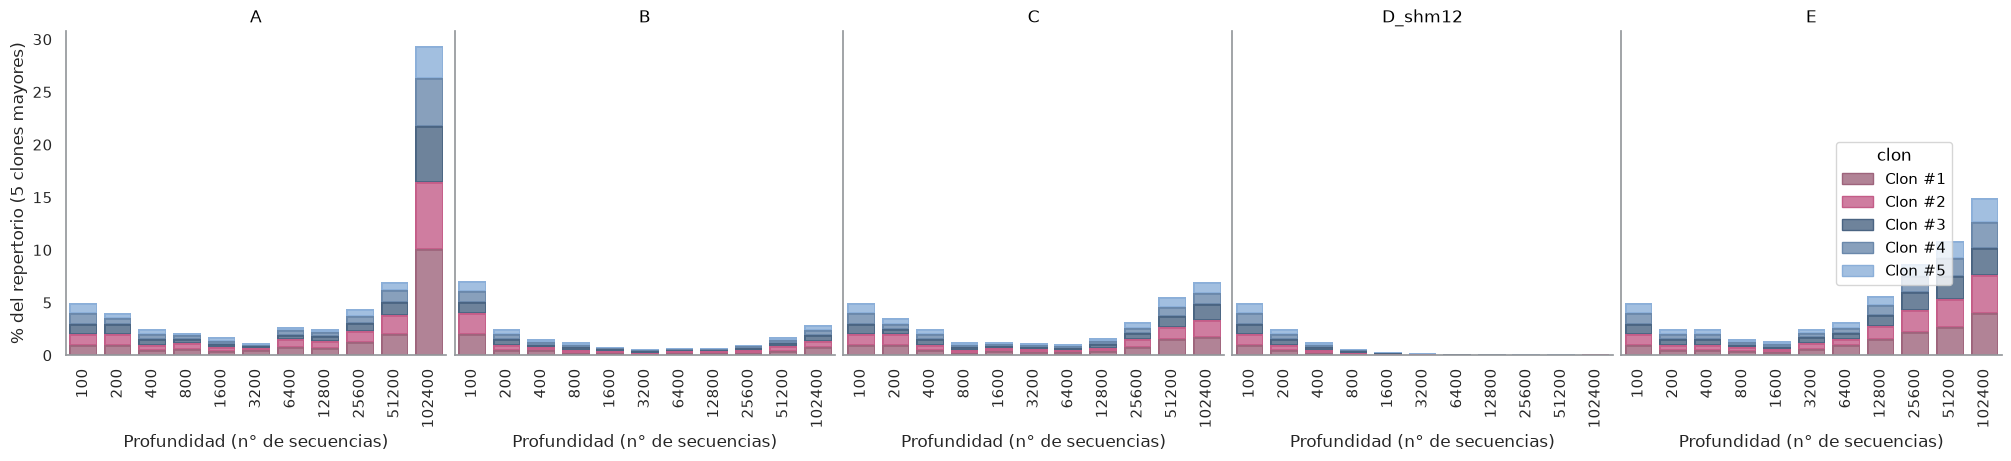

In [10]:
import polars as pl
import seaborn.objects as so
from seaborn import axes_style
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300

base = "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/clonal_table"

# A, B, C y E desde top5_clones.tsv (data/output)
top5_ABCE = (
    pl.read_csv(f"{base}/top5_clones.tsv", separator="\t")
    .filter(pl.col("escenario").is_in(["A", "B", "C", "E"]))
)

# D con SHM 12 % desde top5_clones_D_shm12.tsv (data/shm_12_folicular)
top5_D = pl.read_csv(f"{base}/top5_clones_D_shm12.tsv", separator="\t")

top5_todos = pl.concat([top5_ABCE, top5_D], how="vertical_relaxed")

print(top5_todos.group_by("escenario").len().sort("escenario"))   # debe dar 55 por escenario

# Misma paleta del gráfico de espacio clonal:
# rosados para los clones más grandes, azules para los más pequeños
colormap_top5 = {
    "Clon #1": "#9e647c",
    "Clon #2": "#c45d88",
    "Clon #3": "#4a6482",
    "Clon #4": "#6a88ab",
    "Clon #5": "#8bafd9",
}

# Preparar los datos
df_plot = top5_todos.with_columns(
    profundidad_lbl=pl.col("profundidad").cast(pl.Utf8),
    clon=pl.concat_str(pl.lit("Clon #"), pl.col("ranking").cast(pl.Utf8)),
).sort(["escenario", "profundidad", "ranking"])

orden_prof = [str(p) for p in sorted(top5_todos["profundidad"].unique().to_list())]

plot = (
    so.Plot(
        df_plot,
        x="profundidad_lbl",
        y="porcentaje",
        color="clon",
    )
    .facet(col="escenario")
    .add(so.Bar(alpha=0.8, width=0.8), so.Stack(), legend=True)
    .scale(color=colormap_top5, x=so.Nominal(order=orden_prof))
    .label(x="Profundidad (n° de secuencias)",
           y="% del repertorio (5 clones mayores)")
    .layout(size=(20, 4.5), engine="constrained")
    .theme(
        {
            "axes.edgecolor": "#95999d",
            "axes.spines.right": False,
            "axes.spines.top": False,
        }
    )
)

plot.config.theme.update(axes_style("white"))

fig = plot.plot(pyplot=True)

# Girar las etiquetas del eje X para que no se superpongan
for ax in fig._figure.axes:
    ax.tick_params(axis="x", labelrotation=90)

ruta = "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/plots/top5_clones2"
fig._figure.savefig(ruta + ".png", dpi=300, bbox_inches="tight", facecolor="white")
fig._figure.savefig(ruta + ".svg", format="svg", bbox_inches="tight")